# Generalization analysis — paper figures (C1 audit, C2 UQ, C4 features)
Produces every number and figure for the Water-journal manuscript into `Model/paper_figures/`. Models reuse the hyperparameters tuned in `main_interp_row_42` (fixed across folds so performance differences across folds reflect data nature) and change parameters.

* *main_interp_row_42*: selection and tuning used a row-level split/CV. Rows from the same study could appear in both training and validation folds. Studies later held out by LOSO could also have contributed rows to that earlier selection.

* *main_gener_group_42*: grouped CV keeps studies separate within its tuning folds, so it is better aligned with unseen-study prediction. But its Boruta feature selection and tuning were done on one grouped training partition. Most studies later held out by LOSO may have been in that partition, so their data influenced the choices. The one study held out by main_gener_group_42 itself was excluded from that selection and may not have this particular overlap.

In [14]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import ldh_pipeline as lp

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'savefig.dpi': 300,
})
SEED = lp.SEED
FIG_DIR = lp.MODEL_DIR / 'paper_figures'
FIG_DIR.mkdir(exist_ok=True)
print('Figures ->', FIG_DIR)

Figures -> D:\Research_Projects\GreenX_BaoTien_project\Model\paper_figures


In [15]:
df = lp.load_data(lp.DATA_DIR / '20261028_Data_Adsorption.xlsx')
y = df['RR %']
groups = df['Id'].values
X = df.drop(columns=['Id', 'RR %'])
saved = joblib.load(lp.MODEL_DIR / 'main_interp_row_42' / 'saved_models.joblib')
MODELS = {k: saved[k] for k in ('LR', 'KNN', 'ANN', 'Cubist', 'RF', 'XGB', 'HistGB', 'LGB')}
print(f"{len(df)} rows, {df['Id'].nunique()} studies, {X.shape[1]} features")

1342 rows, 33 studies, 30 features


## Ablation study: Isolate effect of data split

### C1a. Generalization by leave-one-study-out audit
Each of the 33 studies is held out once; models are refit on the remaining 58 with fixed hyperparameters.

In [16]:
loso = lp.loso_evaluation(MODELS, X.reset_index(drop=True), y.reset_index(drop=True), groups)
loso.to_csv(FIG_DIR / 'loso_per_study.csv', index=False)
summary = (loso.groupby('model')[['r2', 'mae', 'rmse']]
           .agg(['mean', 'std']).round(3))
print(summary.columns)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.sort_values('mae_mean').round(2)
summary.to_csv(FIG_DIR / 'loso_summary.csv')
summary

MultiIndex([(  'r2', 'mean'),
            (  'r2',  'std'),
            ( 'mae', 'mean'),
            ( 'mae',  'std'),
            ('rmse', 'mean'),
            ('rmse',  'std')],
           )


,r2_mean,r2_std,mae_mean,mae_std,rmse_mean,rmse_std
model,,,,,,
Cubist,-5.37,17.51,23.33,8.76,26.79,9.57
RF,-8.94,36.34,23.98,8.14,27.14,8.75
HistGB,-7.34,25.08,25.22,9.45,28.59,10.37
LGB,-9.22,32.94,25.70,7.65,29.06,8.38
KNN,-14.67,63.99,28.24,13.46,32.32,14.64
XGB,-12.45,42.93,28.63,10.29,32.61,10.78
LR,-11.03,37.62,29.67,13.75,33.12,14.57
ANN,-14.79,37.08,40.47,22.89,44.10,23.80


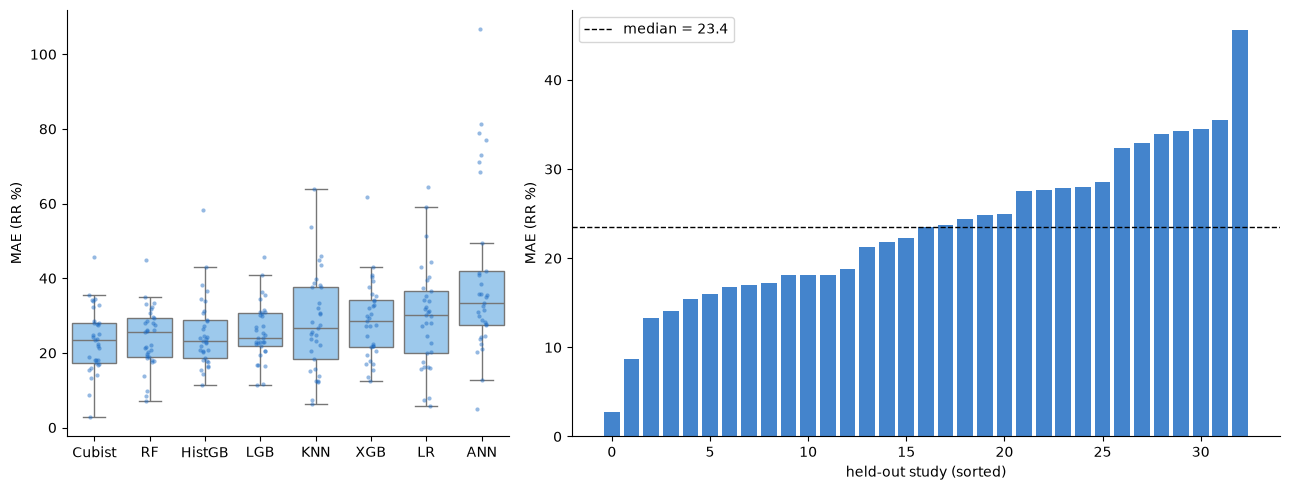

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.6]})
order = summary.index.tolist()
sns.boxplot(data=loso, x='model', y='mae', order=order, ax=axes[0], color='#90CAF9',
            showfliers=False)
sns.stripplot(data=loso, x='model', y='mae', order=order, ax=axes[0], color='#1565C0',
              alpha=0.45, size=3)
axes[0].set_xlabel(''); axes[0].set_ylabel('MAE (RR %)')

best = order[0]
per_study = (loso[loso.model == best].sort_values('mae')
             .reset_index(drop=True))
axes[1].bar(range(len(per_study)), per_study['mae'], color='#1565C0', alpha=0.8)
axes[1].set_xlabel('held-out study (sorted)'); axes[1].set_ylabel('MAE (RR %)')
axes[1].axhline(per_study['mae'].median(), ls='--', color='k', lw=1,
                label=f"median = {per_study['mae'].median():.1f}")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_loso_audit.png', bbox_inches='tight')
plt.show()

### C1b. Interpolation vs unseen-study performance (LOSO)

In [18]:
interp = pd.read_csv(lp.MODEL_DIR / 'main_interp_row_42' / 'model_scores.csv', index_col=0)
loso_med = loso.groupby('model')['mae'].median()
cmp = pd.DataFrame({'interpolation MAE (hold-out)': interp['test_mae'],
                    'unseen-study MAE (LOSO median)': loso_med}).dropna()
cmp = cmp.sort_values('interpolation MAE (hold-out)').round(2)
cmp.to_csv(FIG_DIR / 'interp_vs_loso.csv')
cmp

,interpolation MAE (hold-out),unseen-study MAE (LOSO median)
HistGB,5.40,23.09
LGB,5.71,24.11
XGB,5.91,28.44
KNN,7.45,26.66
Cubist,8.10,23.45
RF,8.39,25.53
ANN,14.48,33.35
LR,18.09,30.22


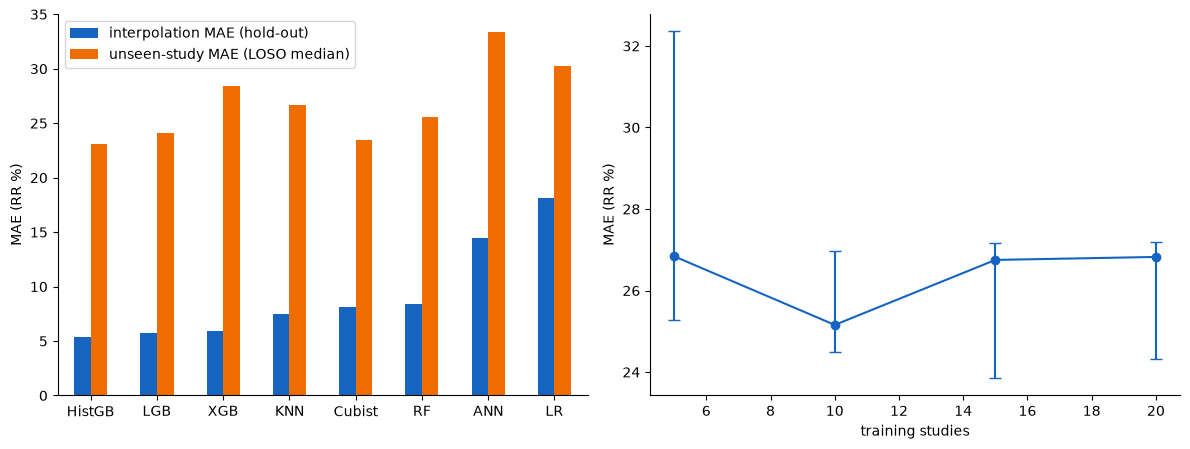

In [24]:
lc = lp.learning_curve_by_studies(MODELS['HistGB'], X, y, groups,
                                  sizes=(5, 10, 15, 20, 35, 30), n_repeats=10)
lc.to_csv(FIG_DIR / 'learning_curve.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cmp.plot.bar(ax=axes[0], rot=0, color=['#1565C0', '#EF6C00'])
axes[0].set_ylabel('MAE (RR %)')

g = lc.groupby('n_studies')['mae']
axes[1].errorbar(g.median().index, g.median(), yerr=[g.median()-g.quantile(0.25),
                 g.quantile(0.75)-g.median()], marker='o', color='#1565C0', capsize=4)
axes[1].set_xlabel('training studies'); axes[1].set_ylabel('MAE (RR %)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_learning_curve.png', bbox_inches='tight')
plt.show()

### C2. Conformal prediction intervals and applicability domain
Split-conformal 90% intervals under both tasks. For the new-study task the calibration set is grouped by study, matching deployment.

In [ ]:
nominal_levels = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
model = MODELS['HistGB']
rows = []

# Interpolation: use the same row-level split for every nominal level.
keep = ~X.duplicated(keep='first')
Xd, yd, gd = X[keep], y[keep], groups[keep]
Xtr, Xte, ytr, yte, _ = lp.make_split(
    Xd, yd, groups=None, test_size=0.2, seed=SEED
)
for nominal in nominal_levels:
    cf = lp.split_conformal(
        model, Xtr, ytr, Xte, yte, alpha=1 - nominal
    )
    rows.append({
        "task": "interpolation",
        "nominal": nominal,
        "coverage": cf["coverage"],
        "half_width_q": cf["q"],
    })

# Unseen studies: use the same grouped split for every nominal level.
Xtr_g, Xte_g, ytr_g, yte_g, gtr = lp.make_split(
    Xd, yd, groups=gd, test_size=0.2, seed=SEED
)
for nominal in nominal_levels:
    cf = lp.split_conformal(
        model, Xtr_g, ytr_g, Xte_g, yte_g,
        alpha=1 - nominal,
        groups_tr=gtr,
    )
    rows.append({
        "task": "unseen studies",
        "nominal": nominal,
        "coverage": cf["coverage"],
        "half_width_q": cf["q"],
    })

conf_table = pd.DataFrame(rows).round(3)
conf_table.to_csv(FIG_DIR / "conformal_coverage.csv", index=False)
conf_table

,task,nominal,coverage,half_width_q
0,interpolation,0.50,0.615,4.194
1,interpolation,0.60,0.690,5.897
2,interpolation,0.70,0.750,8.070
3,interpolation,0.80,0.845,12.595
4,interpolation,0.90,0.929,17.902
5,interpolation,0.95,0.972,30.942
6,unseen studies,0.50,0.720,27.805
7,unseen studies,0.60,0.850,37.364
8,unseen studies,0.70,0.932,46.163
9,unseen studies,0.80,0.949,51.273


### C4. Chemistry-informed features
Adds `pH − pHpzc` (electrostatic driving force), `Ci/AD` (initial loading), and the hydrophobicity interaction; compares both tasks with/without, then reads SHAP dependence mechanistically.

In [22]:
cfg_eng = lp.ExperimentConfig(name='main_interp_row_eng_42', split_mode='row',
                              dedup_features=True, engineered_features=True,
                              models=("Cubist", "RF", "XGB", "HistGB", "LGB"))
run_eng = lp.run_experiment(cfg_eng, df)

X_eng = lp.add_engineered_features(X)
loso_eng = lp.loso_evaluation({'HistGB': run_eng['results']['HistGB']['model']},
                              X_eng.reset_index(drop=True), y.reset_index(drop=True),
                              groups)
feat_cmp = pd.DataFrame({
    'interpolation test MAE': {
        'raw features': interp.loc['HistGB', 'test_mae'],
        'with engineered': run_eng['table'].loc['HistGB', 'test_mae']},
    'unseen-study median MAE': {
        'raw features': loso_med['HistGB'],
        'with engineered': loso_eng['mae'].median()},
}).round(2)
feat_cmp.to_csv(FIG_DIR / 'engineered_features_effect.csv')
feat_cmp

[main_interp_row_eng_42] dropped 83 exact feature-duplicate rows
[main_interp_row_eng_42] split=row  train=1007  test=252  features=33
[BorutaShap] Starting feature selection...


  0%|          | 0/20 [00:00<?, ?it/s]

[BorutaShap] Suggested dropping 9 features.
[BorutaShap] OVERRIDE: Saved 2 Abraham variable(s) from being dropped.
[BorutaShap] Final number of features dropping: 7
[main_interp_row_eng_42] Features remaining after BorutaShap: 26
--- Optuna tuning RF (30 trials) ---
[*] RF best params: {'n_estimators': 200, 'max_depth': 15, 'min_samples_leaf': 3}
--- Optuna tuning XGB (30 trials) ---
[*] XGB best params: {'n_estimators': 235, 'learning_rate': 0.09072348019463952, 'max_depth': 13, 'min_child_weight': 8}
--- Optuna tuning HistGB (30 trials) ---
[*] HistGB best params: {'max_iter': 384, 'learning_rate': 0.0833033984683622, 'max_depth': 12, 'min_samples_leaf': 3}
--- Optuna tuning LGB (30 trials) ---
[*] LGB best params: {'n_estimators': 377, 'learning_rate': 0.10698776201627312, 'max_depth': 14, 'min_child_samples': 9}
--- Cubist ---
[*] best params: {'n_committees': 8, 'neighbors': 1}
    Train      R2  0.9385 | MAE   3.7529
    CV (valid) R2  0.7871 | MAE   8.1439
    Test       R2  0.7

,interpolation test MAE,unseen-study median MAE
raw features,5.40,23.09
with engineered,5.81,25.02


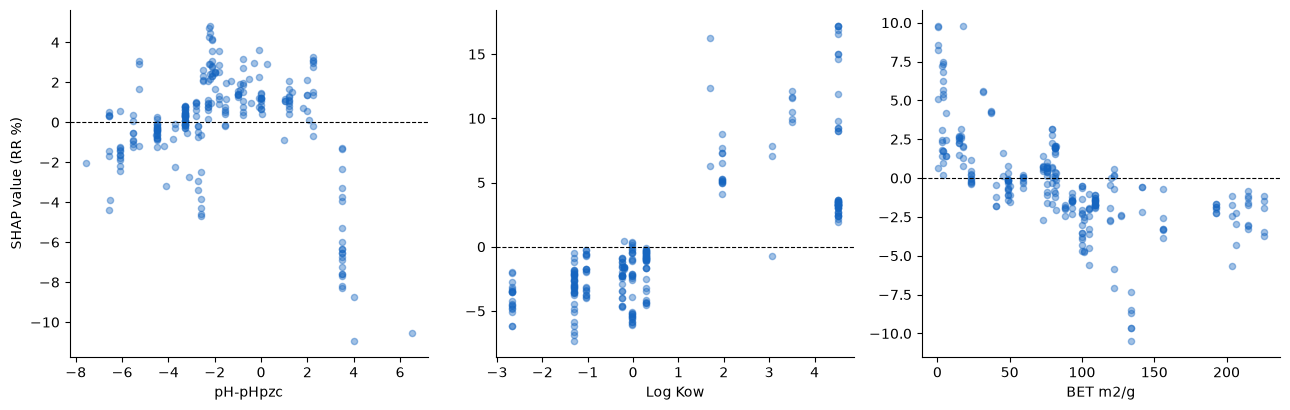

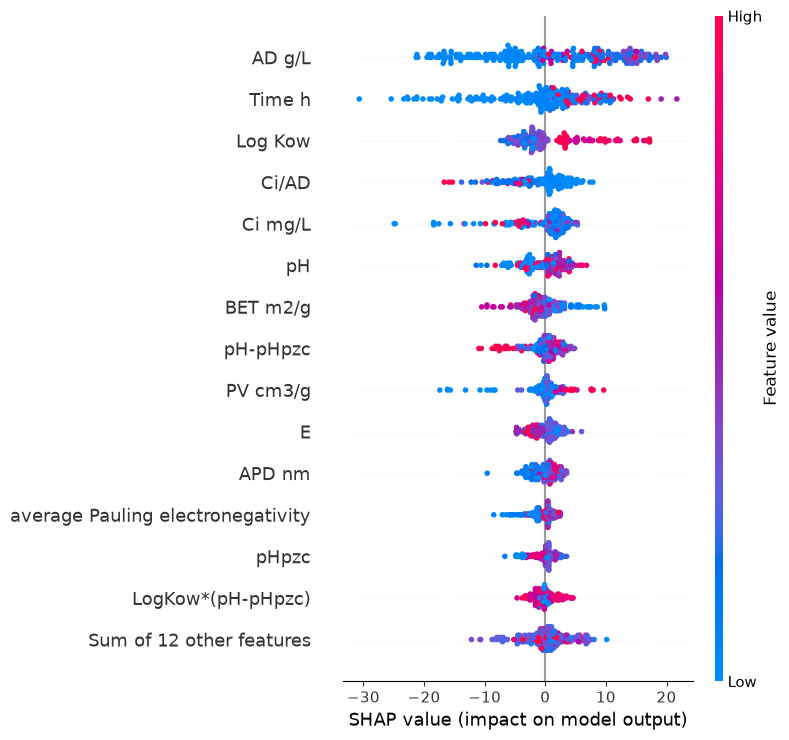

In [28]:
import shap

best_tree = run_eng['table'].sort_values(by=["cv_r2"], ascending=False).index[0]
sv, names = lp.shap_summary(run_eng['results'][best_tree], run_eng['X_test'])
sv.feature_names = names

fig = plt.figure(figsize=(13, 4.2))
for i, feat in enumerate(['pH-pHpzc', 'Log Kow', 'BET m2/g']):
    ax = plt.subplot(1, 3, i + 1)
    j = names.index(feat)
    ax.scatter(sv.data[:, j], sv.values[:, j], alpha=0.4, s=20, color='#1565C0')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_xlabel(feat); ax.set_ylabel('SHAP value (RR %)' if i == 0 else '')
    
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_shap_mechanism.png', bbox_inches='tight')
plt.show()

# Run shap beeswarm plot to show negative and positive effect
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_shap_bar_eng.png', bbox_inches='tight')
plt.show()

## Outputs
All CSVs and figures for the manuscript are in `Model/paper_figures/`; every number cited in the paper traces back to one of these files.